# Member 1 — Classification Track, Part B (Adult / Census Income)

**Review 2 scope (Member 1):** two Part-B algorithms — **Random Forest** and **AdaBoost**.

- Same dataset, cleaning, engineered features, stratified 80:20 split (`random_state=42`) and train-only
  encoder/scaler as Review 1 Part A. The pipeline lives in `adult_prep.py` so every Part-B notebook scores on the
  exact same 9,035 test rows as Part A.
- Metrics (all mandatory): accuracy, weighted precision / recall / F1, confusion matrix, ROC-AUC. Macro F1 and
  balanced accuracy are added because the target is imbalanced (~75% `<=50K`).
- Each model: baseline fit -> hyperparameter tuning with `GridSearchCV` (stratified 5-fold, scored on weighted F1)
  -> improvement documented.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)

from adult_prep import prepare, RANDOM_STATE

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
# joblib workers emit a harmless config-propagation warning on every parallel fit; the env var reaches the workers
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'
# AdaBoost.staged_predict drops the column names internally; the predictions are unaffected
warnings.filterwarnings('ignore', message='X does not have valid feature names')

RESULTS_DIR = Path('../results/classification')
MODELS_DIR = Path('../models/classification')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load the Review 1 preprocessed split

`prepare()` runs the Part A pipeline: pool the two UCI files, drop `?` rows and duplicates, `log1p` the capital
columns, add `net_capital` and `overtime`, drop `fnlwgt` and `education`, stratified 80:20 split, then fit the
one-hot encoder and `StandardScaler` on the **training set only**.

In [2]:
data = prepare('../data/raw/adult')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
class_names = list(data['target_le'].classes_)

print('train:', X_train.shape, '| test:', X_test.shape)
print('share of >50K  train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

train: (36140, 89) | test: (9035, 89)
share of >50K  train: 0.248 | test: 0.248


**Check.** 36,140 training and 9,035 test rows with 89 features and the same ~24.8% `>50K` share in both — identical
to Review 1, so Part A and Part B numbers can go in one table.

In [3]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def score(model, X, y_true):
    """All required metrics for one fitted model on one data set."""
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'accuracy': accuracy_score(y_true, pred),
        'precision_weighted': precision_score(y_true, pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, pred, average='weighted'),
        'f1_weighted': f1_score(y_true, pred, average='weighted'),
        'f1_macro': f1_score(y_true, pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
    }

def tune(estimator, grid):
    """Stratified 5-fold grid search on the training set, ranked by weighted F1."""
    search = GridSearchCV(estimator, grid, scoring='f1_weighted', cv=CV, n_jobs=-1, return_train_score=True)
    search.fit(X_train, y_train)
    return search

results, models = {}, {}

## 2. Random Forest

An ensemble of decision trees, each grown on a bootstrap sample and a random subset of features per split;
averaging many decorrelated trees lowers the variance of a single deep tree (the Part A Decision Tree).

Starting values: `n_estimators=100`, `class_weight='balanced'` to counter the 75/25 imbalance (same choice as the
Part A tree), `min_samples_leaf=5` so leaves are not single people.

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight='balanced',
                                 n_jobs=-1, random_state=RANDOM_STATE)
rf_base.fit(X_train, y_train)
results['Random Forest (base)'] = score(rf_base, X_test, y_test)
pd.Series(results['Random Forest (base)']).round(4)

accuracy              0.8220
precision_weighted    0.8593
recall_weighted       0.8220
f1_weighted           0.8310
f1_macro              0.7888
balanced_accuracy     0.8339
roc_auc               0.9170
dtype: float64

### 2.1 Tuning `n_estimators` (and tree depth)

The guideline asks to tune `n_estimators`. `max_depth` and `min_samples_leaf` are tuned with it because they control
how far each tree can overfit. Scoring is weighted F1 with stratified 5-fold CV on the training set only — the test
set is not touched until the best setting is chosen.

In [5]:
rf_grid = {
    'n_estimators': [100, 200, 400],
    'max_depth': [None, 20],
    'min_samples_leaf': [1, 5],
}
# the grid search parallelises over folds, so each forest is single-threaded (no nested parallelism)
rf_search = tune(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE), rf_grid)
print('best params:', rf_search.best_params_)
print('best CV weighted F1: %.4f' % rf_search.best_score_)

rf_cv = (pd.DataFrame(rf_search.cv_results_)
         [['param_n_estimators', 'param_max_depth', 'param_min_samples_leaf',
           'mean_train_score', 'mean_test_score', 'std_test_score']]
         .sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(rf_cv.round(4))

best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
best CV weighted F1: 0.8357


,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
0,100,None,1,0.9651,0.8357,0.0032
1,400,None,1,0.9664,0.8350,0.0031
2,200,None,1,0.9656,0.8348,0.0028
3,100,20,1,0.8861,0.8331,0.0031
4,400,20,1,0.8867,0.8327,0.0036
5,200,20,1,0.8861,0.8325,0.0039
6,200,None,5,0.8416,0.8295,0.0032
7,400,None,5,0.8416,0.8286,0.0039
8,100,None,5,0.8411,0.8286,0.0044
9,200,20,5,0.8360,0.8249,0.0046


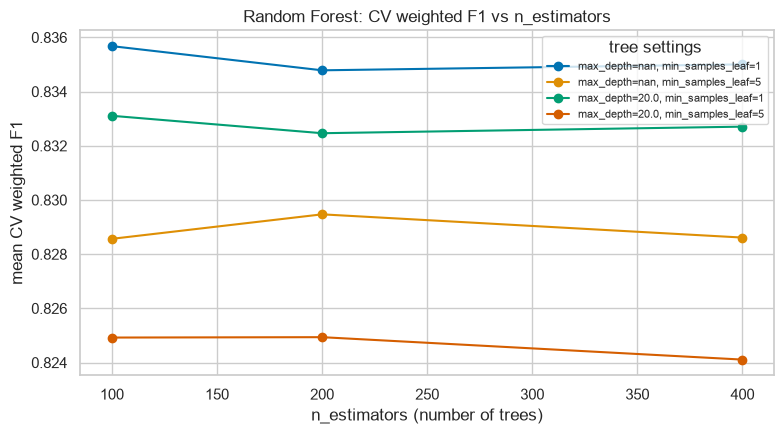

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (depth, leaf), grp in rf_cv.groupby(['param_max_depth', 'param_min_samples_leaf'], dropna=False):
    grp = grp.sort_values('param_n_estimators')
    ax.plot(grp['param_n_estimators'], grp['mean_test_score'], marker='o',
            label=f'max_depth={depth}, min_samples_leaf={leaf}')
ax.set_title('Random Forest: CV weighted F1 vs n_estimators')
ax.set_xlabel('n_estimators (number of trees)')
ax.set_ylabel('mean CV weighted F1')
ax.legend(title='tree settings', fontsize=8)
save_fig('rf_n_estimators_curve.png')
plt.show()

**Observation.**
- The curves are flat in `n_estimators`: 100, 200 and 400 trees differ by less than 0.001 in CV weighted F1, so
  ~100 trees already average away most of the variance and more trees only cost time. CV picks 100.
- Tree size matters more. Fully grown trees (`max_depth=None`, `min_samples_leaf=1`) score best on weighted F1
  (0.836) even though they fit the training folds far better (train F1 0.965) — the forest's averaging absorbs that
  overfitting. Larger leaves (`min_samples_leaf=5`) close the train/CV gap (0.842 vs 0.829) but lose ~0.006 F1.

In [7]:
rf = rf_search.best_estimator_
models['Random Forest'] = rf
results['Random Forest (tuned)'] = score(rf, X_test, y_test)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('Random Forest')}).T.round(4))

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
Random Forest (base),0.822,0.8593,0.822,0.831,0.7888,0.8339,0.9170
Random Forest (tuned),0.833,0.8406,0.833,0.836,0.7844,0.7959,0.8968


**Observation.** Tuning improves the metric it optimised: accuracy +0.011 and weighted F1 +0.005. It is not a free
win: ROC-AUC drops from 0.917 to 0.897 and balanced accuracy from 0.834 to 0.796. Fully grown trees have pure leaves,
so their averaged probabilities are coarser and rank people less well, and they recall fewer `>50K` people. If the
goal were ranking / catching the minority class, the base forest (`min_samples_leaf=5`) would be the better choice.

### 2.2 Feature importance

Impurity-based importance (mean decrease in Gini) of the tuned forest. One-hot columns are summed back to their
original feature so a 41-level `native-country` is not split into 41 tiny bars.

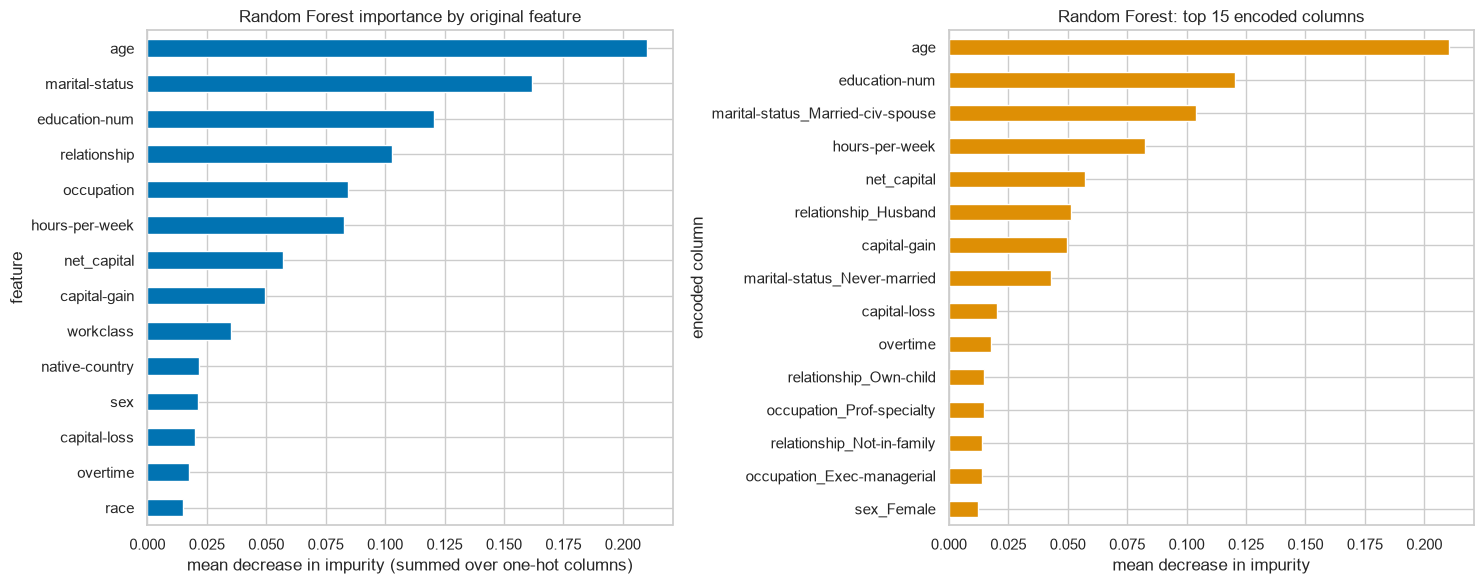

{'age': 0.21, 'marital-status': 0.162, 'education-num': 0.121, 'relationship': 0.103, 'occupation': 0.084, 'hours-per-week': 0.083, 'net_capital': 0.057, 'capital-gain': 0.05, 'workclass': 0.035, 'native-country': 0.022, 'sex': 0.021, 'capital-loss': 0.02, 'overtime': 0.018, 'race': 0.015}


In [8]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns)
cat_prefixes = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
def base_feature(col):
    for p in cat_prefixes:
        if col.startswith(p + '_'):
            return p
    return col
grouped = imp.groupby(base_feature).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
grouped.plot.barh(ax=axes[0], color=sns.color_palette('colorblind')[0])
axes[0].set_title('Random Forest importance by original feature')
axes[0].set_xlabel('mean decrease in impurity (summed over one-hot columns)')
axes[0].set_ylabel('feature')
imp.sort_values().tail(15).plot.barh(ax=axes[1], color=sns.color_palette('colorblind')[1])
axes[1].set_title('Random Forest: top 15 encoded columns')
axes[1].set_xlabel('mean decrease in impurity')
axes[1].set_ylabel('encoded column')
save_fig('rf_feature_importance.png')
plt.show()
print(grouped.sort_values(ascending=False).round(3).to_dict())

**Observation.** `age` (0.21), `marital-status` (0.16), `education-num` (0.12) and `relationship` (0.10) carry
most of the splits — the same signals the Review 1 EDA found (married people and those with 13+ years of education
earn `>50K` far more often). The engineered `net_capital` (0.057) ranks above the raw `capital-gain` (0.050), so the
Review 1 feature is used. `native-country` (0.022) and `race` (0.015) contribute little, matching their heavy
concentration in one value.
Impurity importance favours features with many distinct values (age, hours), so it shows what the forest *uses*,
not a causal effect.

## 3. AdaBoost

Boosting builds an additive model of weak learners **sequentially**: after each round, misclassified rows get a
larger weight so the next learner focuses on them. The default weak learner is a depth-1 tree (a *stump*).
`learning_rate` shrinks each learner's contribution, so it trades off against `n_estimators` — a smaller rate needs
more rounds.

AdaBoost has no `class_weight` option; balanced **sample weights** are passed to `fit` instead so it sees the same
re-weighting as the other models.

In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight

sw_train = compute_sample_weight('balanced', y_train)

ada_base = AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=RANDOM_STATE)
ada_base.fit(X_train, y_train, sample_weight=sw_train)
results['AdaBoost (base)'] = score(ada_base, X_test, y_test)
pd.Series(results['AdaBoost (base)']).round(4)

accuracy              0.8080
precision_weighted    0.8466
recall_weighted       0.8080
f1_weighted           0.8177
f1_macro              0.7723
balanced_accuracy     0.8158
roc_auc               0.9025
dtype: float64

### 3.1 Tuning `n_estimators` and `learning_rate`

Both parameters from the guideline are tuned together because they interact. The balanced sample weights are
routed through `GridSearchCV.fit`, so each CV fold uses the weights of its own training rows.

In [10]:
ada_grid = {
    'n_estimators': [100, 300, 500],
    'learning_rate': [0.1, 0.5, 1.0],
}
ada_search = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), ada_grid, scoring='f1_weighted',
                          cv=CV, n_jobs=-1, return_train_score=True)
ada_search.fit(X_train, y_train, sample_weight=sw_train)
print('best params:', ada_search.best_params_)
print('best CV weighted F1: %.4f' % ada_search.best_score_)

ada_cv = (pd.DataFrame(ada_search.cv_results_)
          [['param_n_estimators', 'param_learning_rate', 'mean_train_score', 'mean_test_score', 'std_test_score']]
          .sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(ada_cv.round(4))

best params: {'learning_rate': 1.0, 'n_estimators': 500}
best CV weighted F1: 0.8275


,param_n_estimators,param_learning_rate,mean_train_score,mean_test_score,std_test_score
0,500,1.0,0.8282,0.8275,0.0040
1,500,0.5,0.8275,0.8270,0.0014
2,300,1.0,0.8269,0.8264,0.0034
3,300,0.5,0.8262,0.8250,0.0019
4,100,1.0,0.8236,0.8233,0.0039
5,100,0.5,0.8194,0.8190,0.0011
6,500,0.1,0.8164,0.8155,0.0020
7,300,0.1,0.8087,0.8073,0.0029
8,100,0.1,0.7878,0.7876,0.0027


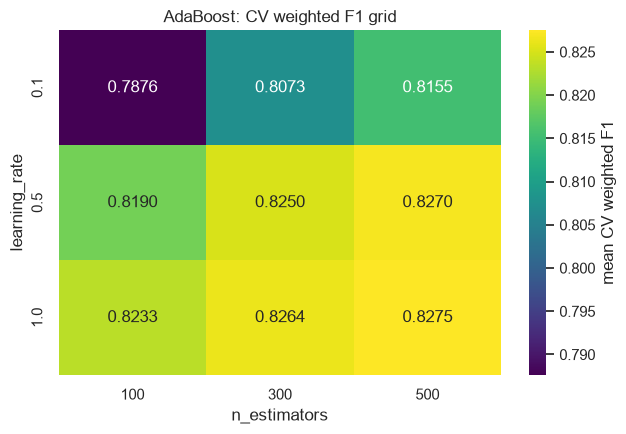

In [11]:
heat = ada_cv.pivot(index='param_learning_rate', columns='param_n_estimators', values='mean_test_score')
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis', cbar_kws={'label': 'mean CV weighted F1'})
plt.title('AdaBoost: CV weighted F1 grid')
plt.xlabel('n_estimators')
plt.ylabel('learning_rate')
save_fig('adaboost_grid_heatmap.png')
plt.show()

**Observation.**
- The trade-off is visible: with `learning_rate=0.1` the score is still climbing at 500 rounds (0.788 -> 0.816), while
  `learning_rate=1.0` is already at 0.823 after 100 rounds. Best: `learning_rate=1.0`, `n_estimators=500` (CV 0.8275).
- That best value sits on the edge of the grid, but 300 -> 500 rounds only adds 0.001, so a larger grid would gain little.
- Train and CV scores differ by less than 0.002 for every setting: unlike the forest, boosted stumps are not
  overfitting here. Their limit is bias, since each stump is a single split.

In [12]:
ada = ada_search.best_estimator_
models['AdaBoost'] = ada
results['AdaBoost (tuned)'] = score(ada, X_test, y_test)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('AdaBoost')}).T.round(4))

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
AdaBoost (base),0.8080,0.8466,0.8080,0.8177,0.7723,0.8158,0.9025
AdaBoost (tuned),0.8138,0.8506,0.8138,0.8231,0.7786,0.8215,0.9097


### 3.2 Staged test score

`staged_predict` gives the prediction after each boosting round, showing how weighted F1 on the test set grows as
stumps are added (diagnostic only — the number of rounds was already chosen by CV).

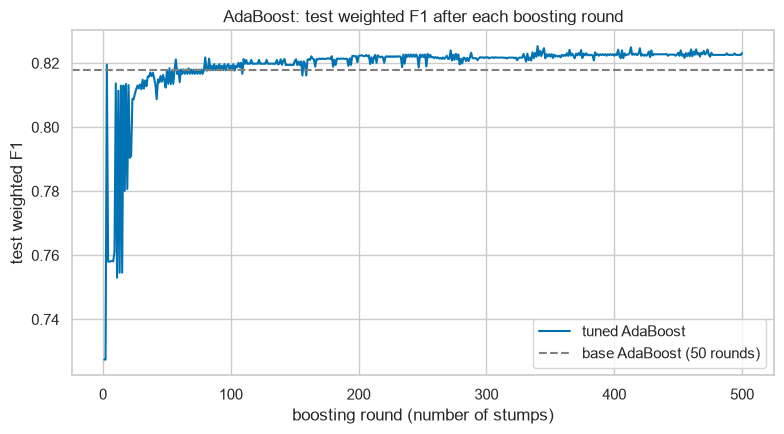

In [13]:
staged_f1 = [f1_score(y_test, p, average='weighted') for p in ada.staged_predict(X_test)]
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(staged_f1) + 1), staged_f1, label='tuned AdaBoost')
plt.axhline(results['AdaBoost (base)']['f1_weighted'], color='grey', ls='--', label='base AdaBoost (50 rounds)')
plt.title('AdaBoost: test weighted F1 after each boosting round')
plt.xlabel('boosting round (number of stumps)')
plt.ylabel('test weighted F1')
plt.legend()
save_fig('adaboost_staged_f1.png')
plt.show()

**Observation.** One stump alone gives weighted F1 0.727; ten rounds already reach 0.814. From 50 rounds (0.818) to 500
(0.823) the curve only creeps up, so most of the tuning gain comes from the extra rounds, at roughly 10x the training time.

## 4. Evaluation of the two tuned models

### 4.1 Tuning improvement

In [14]:
pairs = [('Random Forest', 'Random Forest (base)', 'Random Forest (tuned)'),
         ('AdaBoost', 'AdaBoost (base)', 'AdaBoost (tuned)')]
rows = []
for name, b, t in pairs:
    for metric in ['accuracy', 'f1_weighted', 'f1_macro', 'roc_auc']:
        rows.append({'model': name, 'metric': metric, 'base': results[b][metric], 'tuned': results[t][metric],
                     'change': results[t][metric] - results[b][metric]})
tuning_table = pd.DataFrame(rows)
tuning_table['best_params'] = tuning_table['model'].map({
    'Random Forest': str(rf_search.best_params_), 'AdaBoost': str(ada_search.best_params_)})
display(tuning_table.round(4))
tuning_table.to_csv(RESULTS_DIR / 'partB_member1_tuning_results.csv', index=False)

,model,metric,base,tuned,change,best_params
0,Random Forest,accuracy,0.8220,0.8330,0.0110,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
1,Random Forest,f1_weighted,0.8310,0.8360,0.0050,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
2,Random Forest,f1_macro,0.7888,0.7844,-0.0044,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
3,Random Forest,roc_auc,0.9170,0.8968,-0.0202,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
4,AdaBoost,accuracy,0.8080,0.8138,0.0059,"{'learning_rate': 1.0, 'n_estimators': 500}"
5,AdaBoost,f1_weighted,0.8177,0.8231,0.0054,"{'learning_rate': 1.0, 'n_estimators': 500}"
6,AdaBoost,f1_macro,0.7723,0.7786,0.0063,"{'learning_rate': 1.0, 'n_estimators': 500}"
7,AdaBoost,roc_auc,0.9025,0.9097,0.0072,"{'learning_rate': 1.0, 'n_estimators': 500}"


**Observation.** Tuning was done with CV on the training set only, so these test-set changes are honest estimates.
- **AdaBoost** improves on every metric (accuracy +0.006, weighted F1 +0.005, macro F1 +0.006, ROC-AUC +0.007).
- **Random Forest** improves accuracy (+0.011) and weighted F1 (+0.005), the metric it was tuned on, but loses
  ROC-AUC (-0.020) and macro F1 (-0.004), as explained in section 2.1.

### 4.2 Confusion matrices

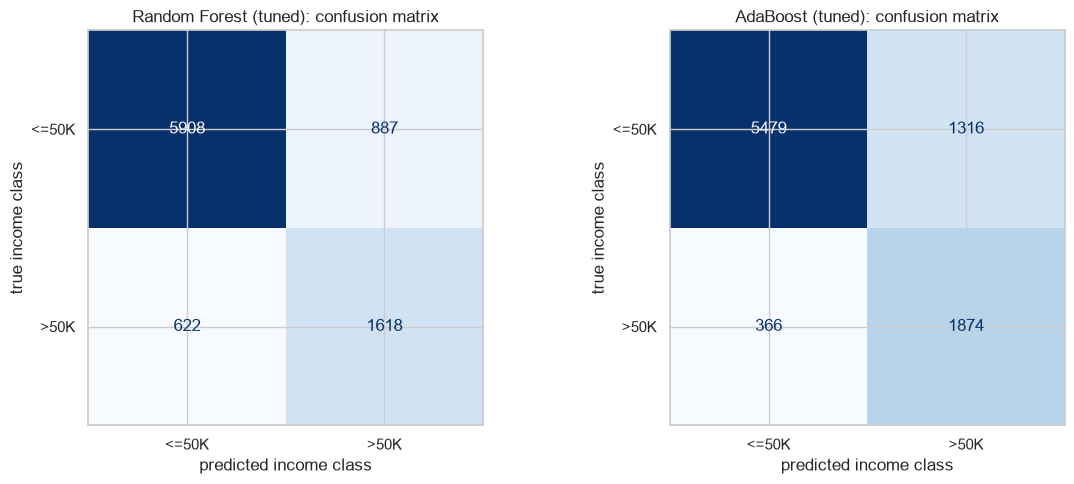

--- Random Forest ---
              precision    recall  f1-score   support

       <=50K      0.905     0.869     0.887      6795
        >50K      0.646     0.722     0.682      2240

    accuracy                          0.833      9035
   macro avg      0.775     0.796     0.784      9035
weighted avg      0.841     0.833     0.836      9035

--- AdaBoost ---


              precision    recall  f1-score   support

       <=50K      0.937     0.806     0.867      6795
        >50K      0.587     0.837     0.690      2240

    accuracy                          0.814      9035
   macro avg      0.762     0.821     0.779      9035
weighted avg      0.851     0.814     0.823      9035



In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name} (tuned): confusion matrix')
    ax.set_xlabel('predicted income class')
    ax.set_ylabel('true income class')
save_fig('partB_member1_confusion_matrices.png')
plt.show()

for name, model in models.items():
    print(f'--- {name} ---')
    print(classification_report(y_test, model.predict(X_test), target_names=class_names, digits=3))

**Observation.** Both models use balanced weights, so most errors are `<=50K` people predicted as `>50K` (top-right
cell) — the cost of catching the minority class.
- AdaBoost catches 84% of `>50K` people but only 59% of its `>50K` predictions are right.
- The Random Forest is more conservative: 72% recall, 65% precision on `>50K`, and fewer false alarms overall,
  which is why its accuracy is higher.

### 4.3 ROC curves

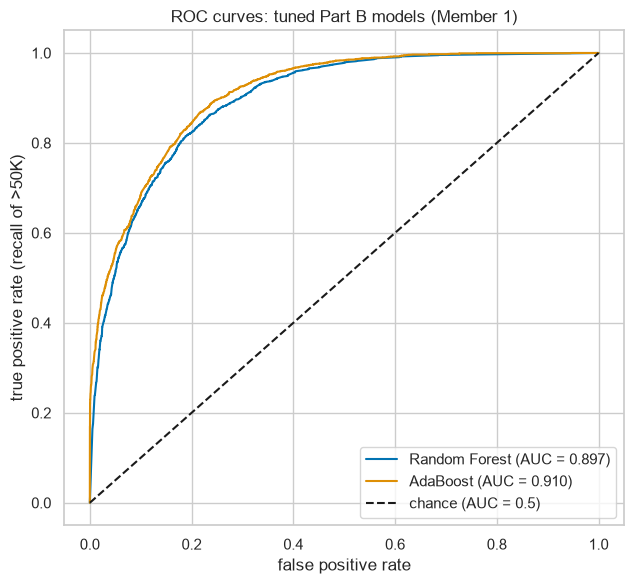

In [16]:
plt.figure(figsize=(6.5, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name + ' (tuned)']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='chance (AUC = 0.5)')
plt.title('ROC curves: tuned Part B models (Member 1)')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate (recall of >50K)')
plt.legend(loc='lower right')
save_fig('partB_member1_roc_curves.png')
plt.show()

### 4.4 5-fold cross-validation of the tuned models

Stratified 5-fold CV on the training set checks that the test-set numbers are not a lucky split.

In [17]:
cv_rows = []
for name, model in models.items():
    fit_params = {'sample_weight': sw_train} if name == 'AdaBoost' else None
    est = clone(model).set_params(n_jobs=1) if 'n_jobs' in model.get_params() else model
    cv = cross_validate(est, X_train, y_train, cv=CV, n_jobs=-1, params=fit_params,
                        scoring=['accuracy', 'f1_weighted', 'roc_auc'])
    cv_rows.append({'model': name,
                    'cv_accuracy_mean': cv['test_accuracy'].mean(), 'cv_accuracy_std': cv['test_accuracy'].std(),
                    'cv_f1_weighted_mean': cv['test_f1_weighted'].mean(), 'cv_f1_weighted_std': cv['test_f1_weighted'].std(),
                    'cv_roc_auc_mean': cv['test_roc_auc'].mean(), 'cv_roc_auc_std': cv['test_roc_auc'].std()})
cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table.round(4))
cv_table.to_csv(RESULTS_DIR / 'partB_member1_cv_results.csv')

,cv_accuracy_mean,cv_accuracy_std,cv_f1_weighted_mean,cv_f1_weighted_std,cv_roc_auc_mean,cv_roc_auc_std
model,,,,,,
Random Forest,0.8320,0.0034,0.8357,0.0032,0.8945,0.0029
AdaBoost,0.8154,0.0039,0.8250,0.0034,0.9131,0.0029


**Observation.** Fold-to-fold standard deviations are at most 0.004, and the CV means match the test-set scores
(RF weighted F1 0.836 CV vs 0.836 test; AdaBoost 0.825 vs 0.823), so both models generalise consistently.

## 5. Comparison with Part A and saved artefacts

The Part A rows come from `results/classification/model_comparison.csv` (Review 1, same split). This is Member 1's
slice of the consolidated table; the other Part-B models are added by their owners.

In [18]:
part_a = pd.read_csv(RESULTS_DIR / 'model_comparison.csv').set_index('model')
part_b = pd.DataFrame({name: results[name + ' (tuned)'] for name in models}).T
part_b.index.name = 'model'
part_b.to_csv(RESULTS_DIR / 'partB_member1_model_comparison.csv')

combined = pd.concat([part_a.assign(part='A'), part_b.assign(part='B')])
cols = ['part', 'accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'roc_auc', 'f1_macro', 'balanced_accuracy']
display(combined[cols].sort_values('f1_weighted', ascending=False).round(4))

for name, model in models.items():
    joblib.dump(model, MODELS_DIR / f"{name.lower().replace(' ', '_')}.pkl", compress=3)
print('saved:', sorted(p.name for p in MODELS_DIR.glob('*.pkl')))

,part,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc,f1_macro,balanced_accuracy
model,,,,,,,,
KNN,A,0.8393,0.8346,0.8393,0.8363,0.8972,0.7767,0.7675
Random Forest,B,0.8330,0.8406,0.8330,0.8360,0.8968,0.7844,0.7959
AdaBoost,B,0.8138,0.8506,0.8138,0.8231,0.9097,0.7786,0.8215
Decision Tree,A,0.8089,0.8490,0.8089,0.8188,0.8942,0.7741,0.8194
SVC,A,0.8071,0.8486,0.8071,0.8172,0.8952,0.7726,0.8188
Logistic Regression,A,0.7997,0.8422,0.7997,0.8103,0.8944,0.7640,0.8095
Majority-class baseline,A,0.7521,0.5656,0.7521,0.6457,0.5000,0.4292,0.5000
Gaussian Naive Bayes,A,0.5856,0.8113,0.5856,0.6051,0.8338,0.5794,0.7033


saved: ['adaboost.pkl', 'classification_onehot_encoder.pkl', 'classification_scaler.pkl', 'decision_tree_classifier.pkl', 'gaussian_nb.pkl', 'income_label_encoder.pkl', 'knn_classifier.pkl', 'logistic_regression.pkl', 'random_forest.pkl', 'svc.pkl']


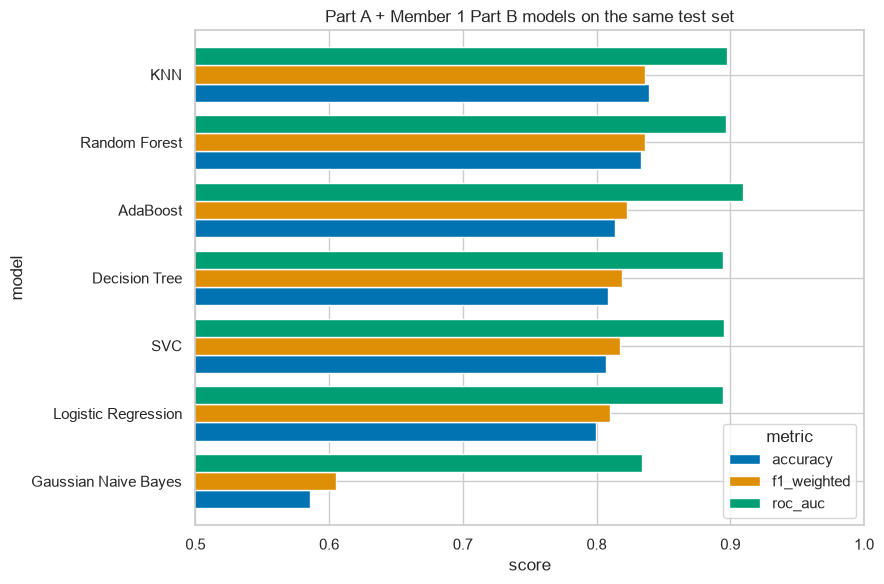

In [19]:
plot_df = combined[combined.index != 'Majority-class baseline'][['accuracy', 'f1_weighted', 'roc_auc']]
plot_df = plot_df.sort_values('f1_weighted')
ax = plot_df.plot.barh(figsize=(9, 6), width=0.8)
ax.set_title('Part A + Member 1 Part B models on the same test set')
ax.set_xlabel('score')
ax.set_ylabel('model')
ax.set_xlim(0.5, 1.0)
ax.legend(title='metric', loc='lower right')
save_fig('partB_member1_vs_partA.png')
plt.show()

## 6. Summary

- **Random Forest** and **AdaBoost** were trained on the Review 1 split, tuned with stratified 5-fold
  `GridSearchCV` (RF: `n_estimators`, `max_depth`, `min_samples_leaf`; AdaBoost: `n_estimators`, `learning_rate`)
  and evaluated on accuracy, weighted precision / recall / F1, ROC-AUC and confusion matrices.
- **Random Forest** (weighted F1 0.836) ties the best Part A model (KNN, 0.836) with higher macro F1 and balanced
  accuracy, so it handles the minority class better.
- **AdaBoost** has the highest ROC-AUC of all eight models so far (0.910) and the best `>50K` recall, but lower
  accuracy because it predicts `>50K` more often.
- Choice depends on the goal: Random Forest for overall accuracy / weighted F1, AdaBoost for ranking and catching
  high earners. The final pick across all ten algorithms is made in the consolidated table.
- Trade-off seen in tuning: fully grown forest trees raise weighted F1 but lower ROC-AUC; AdaBoost is bias-limited
  and gains steadily from more rounds.
- Saved: `models/classification/random_forest.pkl`, `models/classification/adaboost.pkl`, and
  `results/classification/partB_member1_*.csv` / `.png`.